# Stories Coffee: category economics before and after March 2

Compare **Feb 2–Mar 1** with **Mar 2–Mar 29, 2026**, using equal 28-day windows. This companion to the EDA notebook focuses on what to prepare and where, rather than treating company-wide growth as an explanation.

**Colab:** File → Upload notebook → Runtime → Run all. Upload `stories_transactions(1).csv` when prompted. Standard Colab packages are sufficient. The notebook already contains executed outputs from the supplied dataset.

Change `EVENT_DATE` and `WINDOW_DAYS` in the settings cell to explore other windows. Use multiples of seven days for balanced weekday counts. These are descriptive comparisons; they do not estimate a causal conflict effect. Check promotions, prior trends, calendar effects, availability and cost definitions before proposing action.

**Sources:** supplied transaction CSV and hackathon brief. Event-date context: [UN statement, March 17, 2026](https://lebanon.un.org/en/312364-statement-un-humanitarian-coordinator-imran-riza-un-geneva-press-briefing). Confirm that source dates preserve real timing before linking them to external events.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style='whitegrid', palette='colorblind', context='notebook')
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False,
                     'axes.spines.right':False, 'figure.constrained_layout.use':True})
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

CSV_PATH = None  # Optional: '/content/stories_transactions(1).csv'
EVENT_DATE = pd.Timestamp('2026-03-02')
WINDOW_DAYS = 28  # Multiple of 7 gives equal weekday counts on both sides.
REFERENCE_BRANCH = 'Harbour'


## 1. Load and validate
One CSV row is an **item line**, not necessarily an order or a person. Count orders using distinct transaction IDs. Check required fields and accounting identities before interpreting the charts.


In [2]:
if CSV_PATH is None:
    candidates = sorted(Path('.').glob('stories_transactions*.csv'))
    candidates += sorted(Path('upload').glob('stories_transactions*.csv'))
    if len(candidates) == 1:
        CSV_PATH = candidates[0]
    else:
        try:
            from google.colab import files
        except ImportError:
            raise FileNotFoundError('Set CSV_PATH to the CSV you want to analyze.')
        uploaded = files.upload()
        csv_files = [name for name in uploaded if name.lower().endswith('.csv')]
        if len(csv_files) != 1:
            raise ValueError('Upload exactly one transaction CSV, or set CSV_PATH explicitly.')
        CSV_PATH = csv_files[0]

raw = pd.read_csv(CSV_PATH)
required = ['Transaction ID','Date','Time','Branch','Customer ID','Order Type',
            'Product','Category','Quantity','Unit Price (USD)','Discount Rate',
            'Unit Cost (USD)','Line Revenue (USD)','Line Gross Profit (USD)']
missing_columns = sorted(set(required) - set(raw.columns))
if missing_columns:
    raise ValueError(f'Missing columns: {missing_columns}')
print(f'Loaded {Path(CSV_PATH).name}: {len(raw):,} item lines, {raw.shape[1]} columns.')
display(raw.head())


Loaded stories_transactions(1).csv: 51,177 item lines, 14 columns.


,Transaction ID,Date,Time,Branch,Customer ID,Order Type,Product,Category,Quantity,Unit Price (USD),Discount Rate,Unit Cost (USD),Line Revenue (USD),Line Gross Profit (USD)
0,SYN-0000001,2026-01-01,22:37:35,Harbour,C01797,Takeaway,Fresh Orange Juice,Cold Drinks,1,6.040,0.000,2.120,6.040,3.920
1,SYN-0000002,2026-01-01,17:34:07,Garden,NaN,Dine-in,Egg Sandwich,Breakfast,1,8.150,0.000,4.450,8.150,3.700
2,SYN-0000003,2026-01-01,22:45:29,Harbour,NaN,Dine-in,Brownie,Desserts,1,5.410,0.000,2.370,5.410,3.040
3,SYN-0000004,2026-01-01,21:36:38,Uptown,NaN,Dine-in,Iced Mocha,Cold Coffee,1,6.000,0.000,2.140,6.000,3.860
4,SYN-0000005,2026-01-01,12:34:01,Harbour,C01616,Dine-in,Classic Matcha,Matcha & Tea,1,6.770,0.000,2.270,6.770,4.500


In [3]:
df = raw.rename(columns={
    'Transaction ID':'transaction','Date':'date','Time':'time','Branch':'branch',
    'Customer ID':'customer','Order Type':'order_type','Product':'product',
    'Category':'category','Quantity':'quantity','Unit Price (USD)':'price',
    'Discount Rate':'discount','Unit Cost (USD)':'cost',
    'Line Revenue (USD)':'revenue','Line Gross Profit (USD)':'gross_profit'
}).copy()
df['date'] = pd.to_datetime(df['date'], format='%Y-%m-%d', errors='coerce')
clock = pd.to_datetime(df['time'], format='%H:%M:%S', errors='coerce')
df['hour'] = clock.dt.hour
numeric = ['quantity','price','discount','cost','revenue','gross_profit']
for col in numeric:
    df[col] = pd.to_numeric(df[col], errors='coerce')
must_exist = ['transaction','date','hour','branch','order_type','product','category'] + numeric
bad_missing = df[must_exist].isna().sum()
if bad_missing.sum():
    display(bad_missing[bad_missing.gt(0)].rename('Missing / invalid'))
    raise ValueError('Resolve missing required values before continuing.')
if (df['quantity'] <= 0).any() or (~df['discount'].between(0,1)).any():
    raise ValueError('Returns/nonpositive quantities or invalid discounts require a separate treatment.')

rev_error = df['revenue'] - df['quantity'] * df['price'] * (1-df['discount'])
gp_error = df['gross_profit'] - (df['revenue']-df['quantity']*df['cost'])
quality = pd.Series({
    'Item lines':len(df), 'Distinct orders':df['transaction'].nunique(),
    'Products':df['product'].nunique(), 'Branches':df['branch'].nunique(),
    'Exact duplicate rows beyond first':int(raw.duplicated().sum()),
    'Revenue reconciliation errors > $0.01':int(rev_error.abs().gt(.01001).sum()),
    'Gross-profit reconciliation errors > $0.01':int(gp_error.abs().gt(.01001).sum())
}, name='Count')
display(quality.to_frame())
print('Date range:', df['date'].min().date(), 'to', df['date'].max().date())
display(raw.isna().sum().to_frame('Missing item-line values'))
print('Exact duplicate rows are retained: repeated identical items may be valid order entries.')


Date range: 2026-01-01 to 2026-06-30
Exact duplicate rows are retained: repeated identical items may be valid order entries.


,Count
Item lines,51177
Distinct orders,33887
Products,45
Branches,3
Exact duplicate rows beyond first,132
Revenue reconciliation errors > $0.01,0
Gross-profit reconciliation errors > $0.01,0


,Missing item-line values
Transaction ID,0
Date,0
Time,0
Branch,0
Customer ID,18691
Order Type,0
Product,0
Category,0
Quantity,0
Unit Price (USD),0


## 2. Create the right units of analysis
Use **item lines** for product quantities and costs, **orders** for basket value and channel share, and a **branch-day panel** for demand. A missing branch-day is filled with zero recorded orders; this does not prove that the branch was open or closed.


In [4]:
grouped = df.groupby('transaction', sort=False)
consistency = grouped[['date','time','branch','customer','order_type']].nunique(dropna=False).gt(1).sum()
display(consistency.to_frame('Orders with conflicting values'))
if consistency.sum():
    raise ValueError('Transaction IDs do not consistently identify one order; investigate grouping.')
tickets = grouped.agg(date=('date','first'), branch=('branch','first'),
    customer=('customer','first'), order_type=('order_type','first'), hour=('hour','first'),
    revenue=('revenue','sum'), gross_profit=('gross_profit','sum'),
    units=('quantity','sum'), lines=('product','size'), discount=('discount','max')).reset_index()
tickets['takeaway'] = tickets['order_type'].eq('Takeaway')
tickets['discounted'] = tickets['discount'].gt(0)
branches = sorted(df['branch'].unique())
dates = pd.date_range(df['date'].min(),df['date'].max(),freq='D')
grid = pd.MultiIndex.from_product([dates,branches],names=['date','branch'])
daily = tickets.groupby(['date','branch']).agg(orders=('transaction','size'),
    revenue=('revenue','sum'), gross_profit=('gross_profit','sum')).reindex(grid,fill_value=0).reset_index()
daily['weekday'] = daily['date'].dt.dayofweek
print(f'{len(tickets):,} orders; customer ID missing on {tickets.customer.isna().mean():.1%} of orders.')
print('Recorded gross profit excludes expenses not represented by unit cost, such as rent and labor.')


33,887 orders; customer ID missing on 36.5% of orders.
Recorded gross profit excludes expenses not represented by unit cost, such as rent and labor.


,Orders with conflicting values
date,0
time,0
branch,0
customer,0
order_type,0


## 1. Build comparable category measures
Each point represents a **category**, aggregated across the three branches unless stated otherwise. Divide totals by the same number of calendar days. Gross profit per unit is total recorded gross profit divided by total quantity; category-level changes can reflect product mix, branch mix and discounts even when individual products have unchanged prices and costs.

Two different questions need two different y-axes:
- **Gross profit per day:** which categories contribute most to the business?
- **Gross profit per unit:** which categories retain stronger unit economics as their volume changes?


In [5]:
pre_start=EVENT_DATE-pd.Timedelta(days=WINDOW_DAYS)
post_end=EVENT_DATE+pd.Timedelta(days=WINDOW_DAYS-1)
if WINDOW_DAYS % 7:
    print('Warning: this window does not have equal weekday counts.')
if pre_start < df.date.min() or post_end > df.date.max():
    raise ValueError('The requested full windows are not covered by the file.')
period_names=['Before','After']
window=df[df.date.between(pre_start,post_end)].copy()
window['period']=np.where(window.date.lt(EVENT_DATE),'Before','After')
window['discounted_units']=window.quantity*window.discount.gt(0)
window['pre_discount_revenue']=window.quantity*window.price
categories=sorted(df.category.unique())
colors=dict(zip(categories,sns.color_palette('colorblind',n_colors=len(categories))))
category_numbers={category:i+1 for i,category in enumerate(categories)}

def summarize(frame, keys):
    out=frame.groupby(keys,observed=True).agg(units=('quantity','sum'),
        revenue=('revenue','sum'),gp=('gross_profit','sum'),
        discounted_units=('discounted_units','sum'),list_revenue=('pre_discount_revenue','sum'))
    out['units_per_day']=out.units/WINDOW_DAYS
    out['gp_per_day']=out.gp/WINDOW_DAYS
    out['gp_per_unit']=out.gp/out.units.replace(0,np.nan)
    out['gross_margin_pct']=100*out.gp/out.revenue.replace(0,np.nan)
    out['discounted_unit_pct']=100*out.discounted_units/out.units.replace(0,np.nan)
    out['effective_discount_pct']=100*(out.list_revenue-out.revenue)/out.list_revenue.replace(0,np.nan)
    return out

cat=summarize(window,['category','period'])
bc=summarize(window,['category','branch','period'])
print(f'Before: {pre_start:%b %d} to {EVENT_DATE-pd.Timedelta(days=1):%b %d, %Y}')
print(f'After:  {EVENT_DATE:%b %d} to {post_end:%b %d, %Y}')
print(f'{WINDOW_DAYS} calendar days per period; exact duplicate lines are retained.')
display(cat[['units_per_day','gp_per_day','gp_per_unit','gross_margin_pct','discounted_unit_pct']].round(2))


Before: Feb 02 to Mar 01, 2026
After:  Mar 02 to Mar 29, 2026
28 calendar days per period; exact duplicate lines are retained.


units_per_day  gp_per_day  gp_per_unit  gross_margin_pct  \
category     period                                                             
Bakery       After          59.890     147.440        2.460            60.200   
             Before         58.860     145.230        2.470            60.270   
Breakfast    After          13.360      61.820        4.630            53.310   
             Before         12.570      58.150        4.630            53.180   
Cold Coffee  After          40.610     139.940        3.450            66.100   
             Before         35.610     126.710        3.560            66.250   
Cold Drinks  After          29.790      73.530        2.470            63.990   
             Before         28.710      69.100        2.410            62.950   
Desserts     After          25.710      73.240        2.850            47.070   
             Before         22.790      67.460        2.960            47.710   
Hot Coffee   After          45.750     139.690        3.050            66.790   
             Before         41.390     128.010        3.090            66.690   
Matcha & Tea After          44.110     168.860        3.830            60.860   
             Before         38.570     148.430        3.850            61.040   
Meals        After           8.070      44.060        5.460            50.830   
             Before          6.430      34.210        5.320            50.740   
Sandwiches   After          20.390     100.850        4.950            49.690   
             Before         19.140      92.990        4.860            48.810   

                     discounted_unit_pct  
category     period                       
Bakery       After                 5.900  
             Before                5.400  
Breakfast    After                 8.290  
             Before                3.690  
Cold Coffee  After                17.680  
             Before                6.020  
Cold Drinks  After                 5.280  
             Before                5.720  
Desserts     After                17.780  
             Before                3.130  
Hot Coffee   After                 5.700  
             Before                7.160  
Matcha & Tea After                 5.180  
             Before                5.740  
Meals        After                 3.540  
             Before                3.890  
Sandwiches   After                 4.900  
             Before                6.340

## 2. Your proposed scatter: units versus gross profit, before and after
**X:** category units sold per day. **Y:** category gross profit per day. Identical scales, colors and category numbers make the panels comparable. Top-right categories have larger observed contributions; movement there can come simply from increased volume, so this is not a margin-improvement claim.


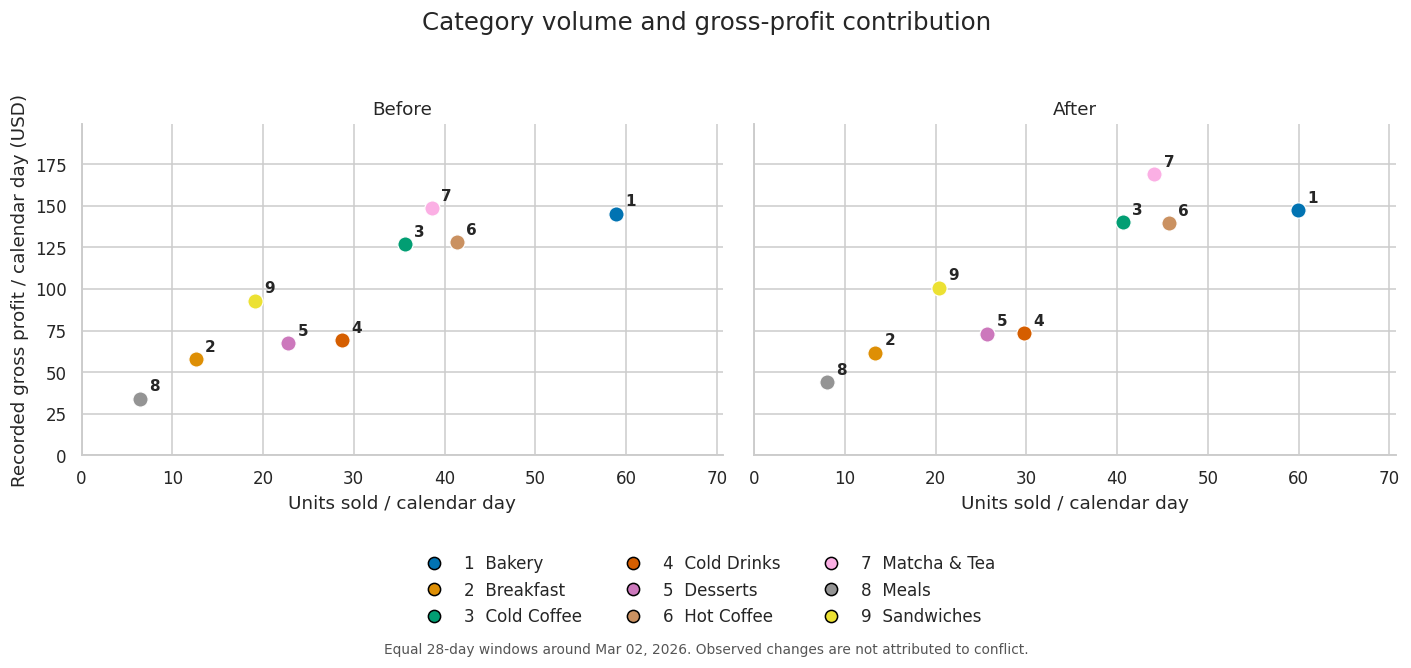

In [6]:
from matplotlib.lines import Line2D
plt.rcParams['figure.constrained_layout.use']=False
fig,axes=plt.subplots(1,2,figsize=(13,6),sharex=True,sharey=True)
xmax=cat.units_per_day.max()*1.18
ymax=cat.gp_per_day.max()*1.18
for ax,period in zip(axes,period_names):
    part=cat.xs(period,level='period')
    for category in categories:
        if category not in part.index:
            continue
        row=part.loc[category]
        ax.scatter(row.units_per_day,row.gp_per_day,s=100,color=colors[category],edgecolor='white',linewidth=.8)
        ax.annotate(str(category_numbers[category]),(row.units_per_day,row.gp_per_day),
                    xytext=(6,5),textcoords='offset points',fontsize=10,fontweight='bold')
    ax.set(title=period,xlabel='Units sold / calendar day',xlim=(0,xmax),ylim=(0,ymax))
axes[0].set_ylabel('Recorded gross profit / calendar day (USD)')
handles=[Line2D([0],[0],marker='o',color='none',markerfacecolor=colors[c],markersize=8,
                label=f'{category_numbers[c]}  {c}') for c in categories]
fig.legend(handles=handles,loc='lower center',ncol=3,frameon=False,bbox_to_anchor=(.5,.025))
fig.suptitle('Category volume and gross-profit contribution',fontsize=16,y=.98)
fig.text(.5,.005,f'Equal {WINDOW_DAYS}-day windows around {EVENT_DATE:%b %d, %Y}. Observed changes are not attributed to conflict.',ha='center',fontsize=9,color='#555555')
fig.tight_layout(rect=[0,.19,1,.94])
plt.show()


## 3. A more diagnostic scatter: volume versus profit per unit
An open circle is **before**; a filled circle is **after**. Arrows show the direction of change for the same category. Moving right means higher units/day. Moving down means lower recorded profit per unit. Even this unit-contribution change can be caused by a different mix of products or branches; inspect the branch view next.


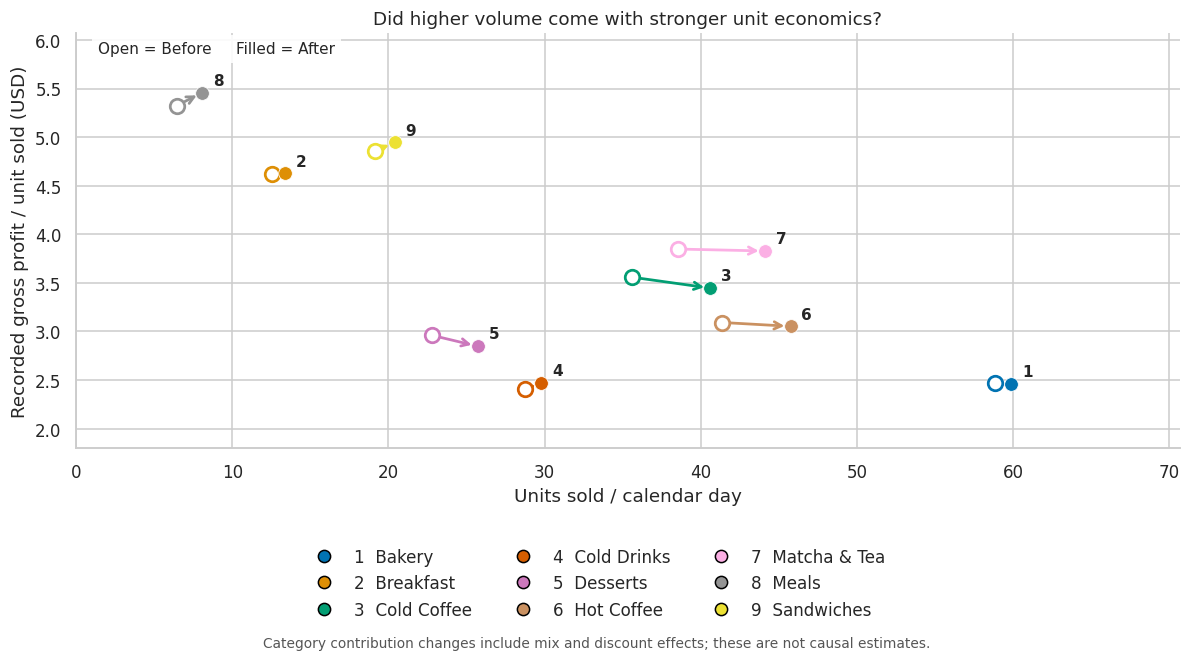

In [7]:
fig,ax=plt.subplots(figsize=(11,6))
for category in categories:
    if any((category,p) not in cat.index for p in period_names):
        continue
    a=cat.loc[(category,'Before')]
    b_=cat.loc[(category,'After')]
    color=colors[category]
    ax.annotate('',xy=(b_.units_per_day,b_.gp_per_unit),xytext=(a.units_per_day,a.gp_per_unit),
                arrowprops={'arrowstyle':'->','color':color,'lw':1.8,'shrinkA':4,'shrinkB':4})
    ax.scatter(a.units_per_day,a.gp_per_unit,s=90,facecolors='white',edgecolors=[color],linewidth=1.8,zorder=3)
    ax.scatter(b_.units_per_day,b_.gp_per_unit,s=80,color=color,edgecolors='white',linewidth=.5,zorder=4)
    ax.annotate(str(category_numbers[category]),(b_.units_per_day,b_.gp_per_unit),xytext=(7,5),
                textcoords='offset points',fontsize=10,fontweight='bold')
ax.set(xlabel='Units sold / calendar day',ylabel='Recorded gross profit / unit sold (USD)',
       title='Did higher volume come with stronger unit economics?',xlim=(0,cat.units_per_day.max()*1.18))
ax.margins(y=.2)
ax.text(.02,.98,'Open = Before     Filled = After',transform=ax.transAxes,va='top',fontsize=10,
        bbox={'facecolor':'white','alpha':.9,'edgecolor':'none'})
fig.legend(handles=handles,loc='lower center',ncol=3,frameon=False,bbox_to_anchor=(.5,.025))
fig.text(.5,.005,'Category contribution changes include mix and discount effects; these are not causal estimates.',ha='center',fontsize=9,color='#555555')
fig.tight_layout(rect=[0,.19,1,1])
plt.show()


## 4. Is the change concentrated in a branch or associated with discounts?
These three heatmaps separate **volume**, **profit per unit**, and **discount exposure**. Scales differ between metrics and are shared across branches within a metric. The third panel is a percentage-point change, not a percent change. More discounted units do not by themselves prove that discounts caused extra sales.


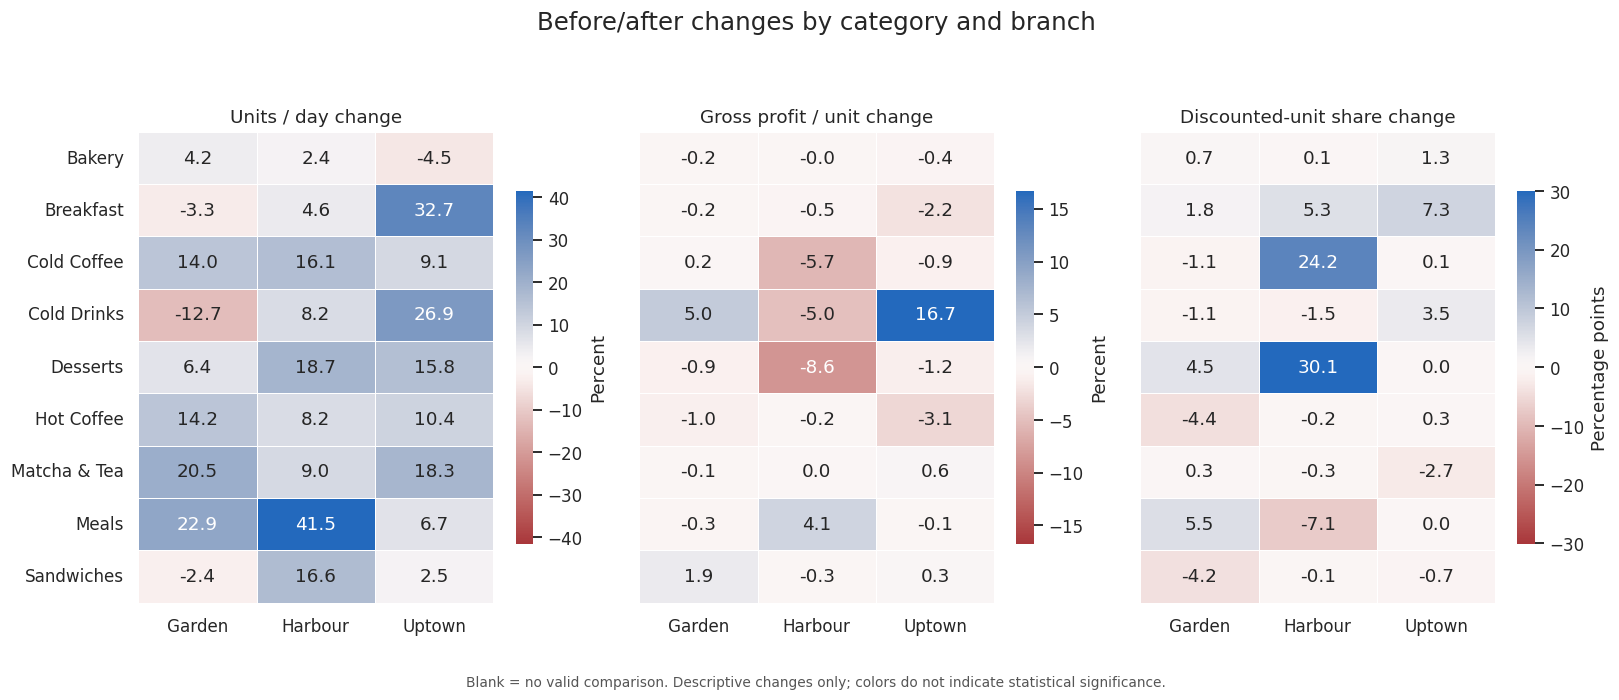

units_change_pct  gp_per_unit_change_pct  \
category     branch                                              
Bakery       Garden              4.160                  -0.190   
             Harbour             2.410                  -0.010   
             Uptown             -4.500                  -0.410   
Breakfast    Garden             -3.280                  -0.160   
             Harbour             4.570                  -0.490   
             Uptown             32.730                  -2.220   
Cold Coffee  Garden             14.010                   0.220   
             Harbour            16.080                  -5.730   
             Uptown              9.090                  -0.900   
Cold Drinks  Garden            -12.670                   5.040   
             Harbour             8.200                  -4.950   
             Uptown             26.870                  16.730   
Desserts     Garden              6.430                  -0.890   
             Harbour            18.680                  -8.580   
             Uptown             15.840                  -1.160   
Hot Coffee   Garden             14.170                  -1.000   
             Harbour             8.200                  -0.210   
             Uptown             10.390                  -3.080   
Matcha & Tea Garden             20.470                  -0.110   
             Harbour             8.960                   0.020   
             Uptown             18.320                   0.570   
Meals        Garden             22.860                  -0.270   
             Harbour            41.540                   4.080   
             Uptown              6.670                  -0.090   
Sandwiches   Garden             -2.420                   1.860   
             Harbour            16.590                  -0.250   
             Uptown              2.500                   0.270   

                      discounted_unit_change_pp  
category     branch                              
Bakery       Garden                       0.700  
             Harbour                      0.100  
             Uptown                       1.350  
Breakfast    Garden                       1.830  
             Harbour                      5.310  
             Uptown                       7.320  
Cold Coffee  Garden                      -1.060  
             Harbour                     24.160  
             Uptown                       0.080  
Cold Drinks  Garden                      -1.070  
             Harbour                     -1.460  
             Uptown                       3.490  
Desserts     Garden                       4.550  
             Harbour                     30.060  
             Uptown                       0.040  
Hot Coffee   Garden                      -4.420  
             Harbour                     -0.200  
             Uptown                       0.300  
Matcha & Tea Garden                       0.270  
             Harbour                     -0.290  
             Uptown                      -2.670  
Meals        Garden                       5.550  
             Harbour                     -7.060  
             Uptown                       0.000  
Sandwiches   Garden                      -4.170  
             Harbour                     -0.060  
             Uptown                      -0.750

In [8]:
before=bc.xs('Before',level='period')
after=bc.xs('After',level='period')
change=pd.DataFrame(index=before.index.union(after.index))
change['units_change_pct']=100*(after.units_per_day/before.units_per_day.replace(0,np.nan)-1)
change['gp_per_unit_change_pct']=100*(after.gp_per_unit/before.gp_per_unit.replace(0,np.nan)-1)
change['discounted_unit_change_pp']=after.discounted_unit_pct-before.discounted_unit_pct
fig,axes=plt.subplots(1,3,figsize=(15,6.3),sharey=True)
specs=[('units_change_pct','Units / day change','Percent'),
       ('gp_per_unit_change_pct','Gross profit / unit change','Percent'),
       ('discounted_unit_change_pp','Discounted-unit share change','Percentage points')]
for ax,(metric,title,unit_label) in zip(axes,specs):
    values=change[metric].unstack('branch').reindex(index=categories,columns=branches)
    limit=max(float(np.nanmax(abs(values.to_numpy()))),.01)
    sns.heatmap(values,ax=ax,annot=True,fmt='.1f',cmap='vlag_r',center=0,vmin=-limit,vmax=limit,
                linewidths=.5,cbar_kws={'label':unit_label,'shrink':.75},mask=values.isna())
    ax.set(title=title,xlabel='',ylabel='')
    ax.tick_params(axis='x',rotation=0)
    ax.tick_params(axis='y',rotation=0)
fig.suptitle('Before/after changes by category and branch',fontsize=16,y=.99)
fig.text(.5,.015,'Blank = no valid comparison. Descriptive changes only; colors do not indicate statistical significance.',ha='center',fontsize=9,color='#555555')
fig.tight_layout(rect=[0,.06,1,.94])
plt.show()
display(change.round(2))


## 5. Check whether category changes persist across window lengths
Use 14, 28 and 42 days on each side, where coverage permits. A direction that reverses with the window deserves a weaker interpretation. These overlapping comparisons are sensitivity checks, not independent replications. All growth below is in units/day, not a causal conflict effect.


In [9]:
rows=[]
for days in [14,28,42]:
    start=EVENT_DATE-pd.Timedelta(days=days)
    end=EVENT_DATE+pd.Timedelta(days=days-1)
    if start < df.date.min() or end > df.date.max():
        continue
    x=df[df.date.between(start,end)].copy()
    x['period']=np.where(x.date.lt(EVENT_DATE),'Before','After')
    units=x.groupby(['category','period']).quantity.sum().unstack()
    for category,row in units.iterrows():
        old=row.get('Before',np.nan);new=row.get('After',np.nan)
        rows.append({'category':category,'days_each_side':days,
                     'units_change_pct':100*(new/old-1) if old>0 else np.nan})
sensitivity=pd.DataFrame(rows).pivot(index='category',columns='days_each_side',values='units_change_pct')
display(sensitivity.round(1))
print('A percentage share can fall even when absolute units rise. Check both measures.')


A percentage share can fall even when absolute units rise. Check both measures.


days_each_side,14,28,42
category,,,
Bakery,6.200,1.800,10.500
Breakfast,29.900,6.200,3.900
Cold Coffee,12.000,14.000,19.500
Cold Drinks,20.100,3.700,13.800
Desserts,16.200,12.900,21.900
Hot Coffee,12.600,10.500,15.400
Matcha & Tea,11.700,14.400,18.600
Meals,46.200,25.600,23.600
Sandwiches,9.000,6.500,11.100


## From a chart to a decision

| Observed pattern | Next investigation | Possible operating action to test |
|---|---|---|
| Category volume rises across several windows | Is the increase persistent after accounting for trend and promotions? | Adjust preparation quantities using recent demand |
| Volume rises while profit/unit falls | Check discounted units, product mix and branch mix | Test promotion design or a different product mix |
| Growth is concentrated in one branch | Check basket composition, availability and branch-specific promotions | Use branch-specific preparation targets |
| A category loses share but gains units | Separate relative mix from absolute demand | Avoid cutting preparation solely because share fell |

Do not conclude from these graphs that conflict caused the changes, discounts generated incremental demand, or higher sales required a particular staffing level. The file has no inventory, waste, stockout, capacity or labor data. Validate a preparation policy chronologically against a previous-weekday baseline, and label waste/shortage costs as assumptions.

**Recommended figure selection for the submission:** the movement scatter, the branch/category heatmaps, and an actual-versus-predicted demand plot with a properly validated baseline. Use the first scatter as a clear descriptive overview.
